# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Muhammad Fardan Hafidz | 5054251021 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# Set style visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 10

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.

data_path = 'Live.csv' if os.path.exists('Live.csv') else '6. Tugas_KMeans_Hierarchical Clustering/Live.csv'
df = pd.read_csv(data_path)

print(f"Dimensi dataset awal: {df.shape[0]} baris x {df.shape[1]} kolom\n")
print("=== Informasi Dataset (df.info()) ===")
df.info()

print("\n=== Jumlah Missing Value per Kolom ===")
display(df.isnull().sum())

print("\n=== Statistik Deskriptif ===")
display(df.describe())

print(f"\nJumlah baris duplikat identik (seluruh kolom): {df.duplicated().sum()}")
print(f"Jumlah status_id duplikat: {df.duplicated(subset=['status_id']).sum()}")
print(f"Jumlah baris duplikat jika kolom status_id diabaikan: {df.drop(columns=['status_id']).duplicated().sum()}")

# Periksa kolom yang seluruhnya kosong
empty_cols = [c for c in df.columns if df[c].isnull().all()]
print(f"\nKolom yang seluruhnya kosong (100% NaN): {empty_cols}")

Dimensi dataset awal: 7050 baris x 16 kolom

=== Informasi Dataset (df.info()) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column

status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64


=== Statistik Deskriptif ===


,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN



Jumlah baris duplikat identik (seluruh kolom): 0
Jumlah status_id duplikat: 0
Jumlah baris duplikat jika kolom status_id diabaikan: 54

Kolom yang seluruhnya kosong (100% NaN): ['Column1', 'Column2', 'Column3', 'Column4']


=== Ringkasan Karakteristik Fitur Hitungan ===


,Fitur,Skewness,Nilai Max,Median,Proporsi Nol (%)
0,num_reactions,3.738452,4710,59.5,1.716312
1,num_comments,9.028850,20990,4.0,30.056738
2,num_shares,7.099332,3424,0.0,55.475177
3,num_likes,3.919128,4710,58.0,1.787234
4,num_loves,6.004845,657,0.0,60.000000
5,num_wows,18.246813,278,0.0,75.290780
6,num_hahas,20.305741,157,0.0,83.914894
7,num_sads,17.578868,51,0.0,91.390071
8,num_angrys,19.507129,31,0.0,94.000000


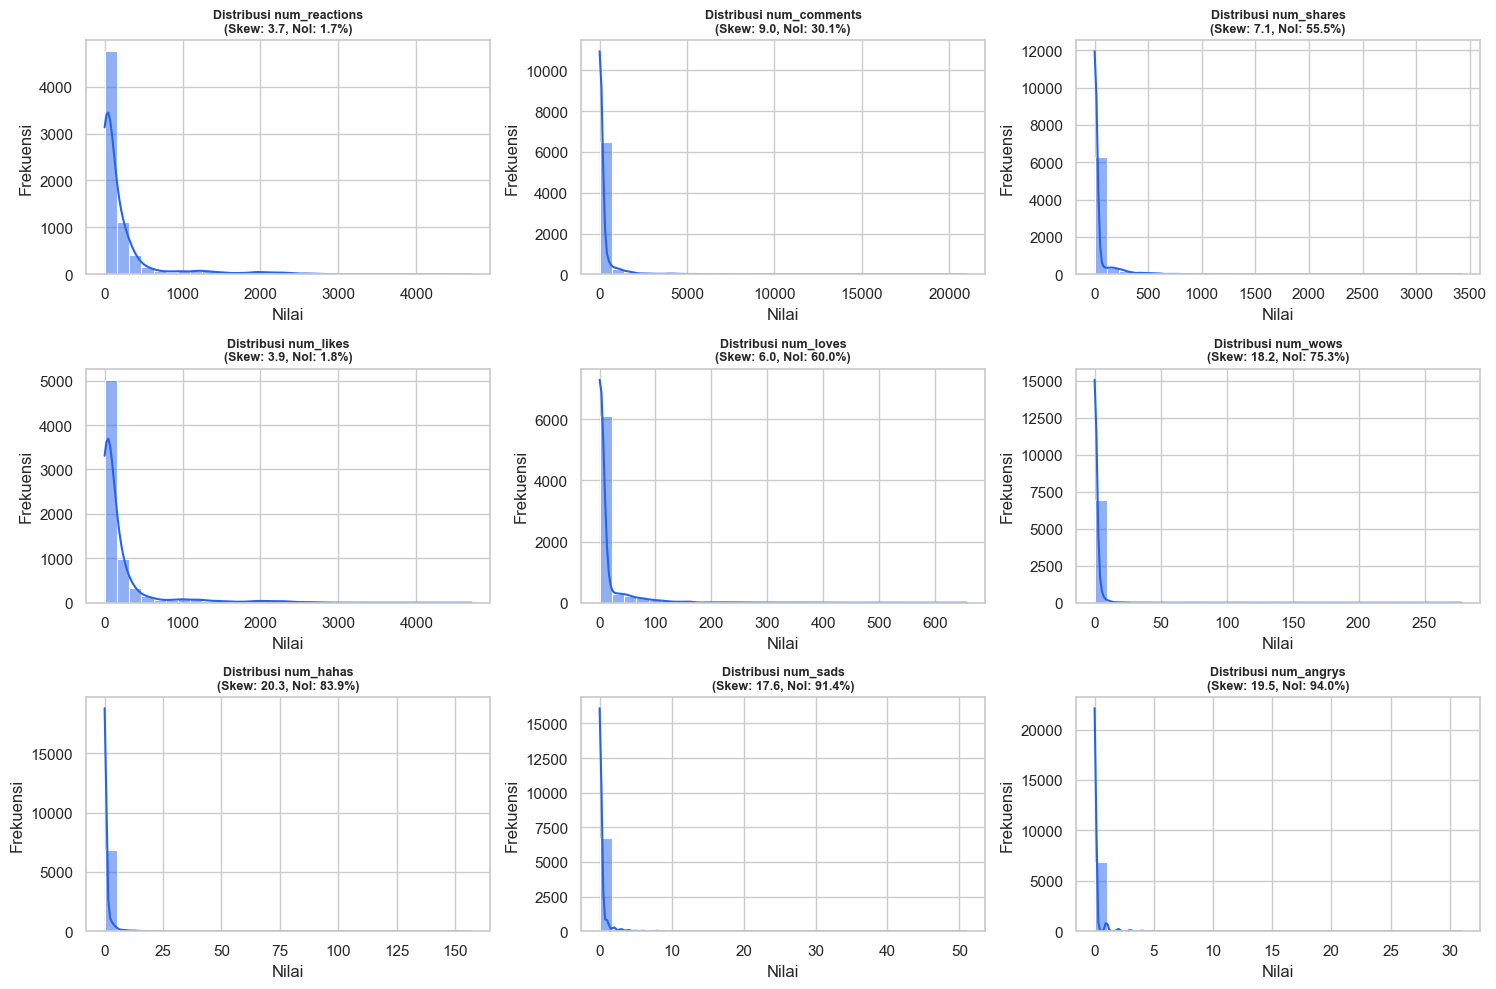

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.

count_cols = [
    'num_reactions', 'num_comments', 'num_shares', 'num_likes',
    'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys'
]

# Tampilkan ringkasan skewness, nilai maksimum, dan proporsi nilai nol
skew_summary = []
for c in count_cols:
    skew_summary.append({
        'Fitur': c,
        'Skewness': df[c].skew(),
        'Nilai Max': df[c].max(),
        'Median': df[c].median(),
        'Proporsi Nol (%)': (df[c] == 0).mean() * 100
    })
df_skew = pd.DataFrame(skew_summary)
print("=== Ringkasan Karakteristik Fitur Hitungan ===")
display(df_skew)

# Visualisasi Boxplot dan Histogram
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(count_cols):
    sns.histplot(df[col], kde=True, bins=30, color='#2563eb', ax=axes[i])
    axes[i].set_title(f"Distribusi {col}\n(Skew: {df[col].skew():.1f}, Nol: {(df[col]==0).mean()*100:.1f}%)", fontsize=9, fontweight='bold')
    axes[i].set_xlabel('Nilai')
    axes[i].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

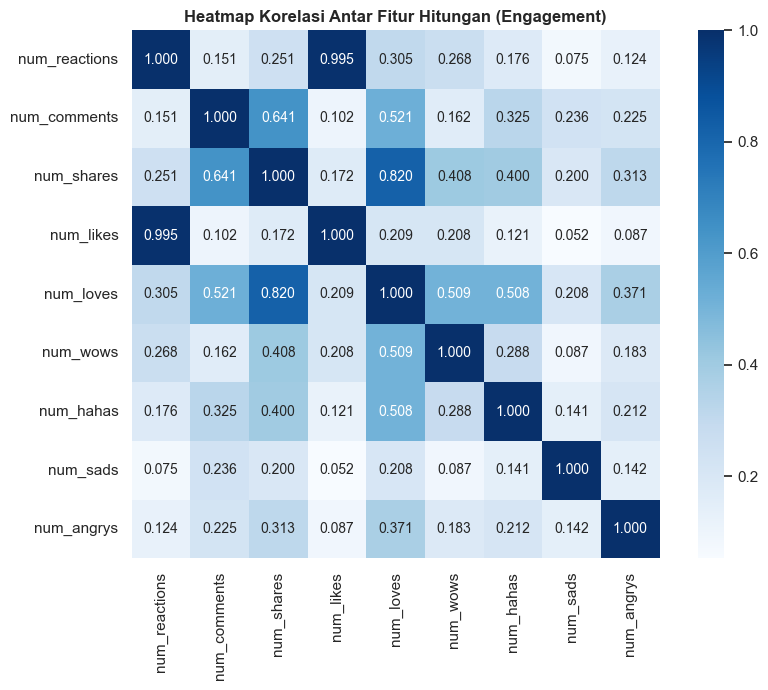

Korelasi Pearson antara num_reactions dan num_likes: 0.99492
num_reactions hampir identik dengan num_likes, menandakan redundansi informasi yang sangat tinggi.


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.

corr_counts = df[count_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_counts, annot=True, fmt='.3f', cmap='Blues', cbar=True, square=True)
plt.title('Heatmap Korelasi Antar Fitur Hitungan (Engagement)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# Hubungan num_reactions vs num_likes
corr_reactions_likes = df['num_reactions'].corr(df['num_likes'])
print(f"Korelasi Pearson antara num_reactions dan num_likes: {corr_reactions_likes:.5f}")
print("num_reactions hampir identik dengan num_likes, menandakan redundansi informasi yang sangat tinggi.")

=== Statistik Posting dan Keberadaan Reaksi Emoji per Tahun ===


,year,total_posting,posting_ber_emoji,proporsi_emoji_persen
0,2012,589,0,0.000000
1,2013,500,0,0.000000
2,2014,233,0,0.000000
3,2015,337,0,0.000000
4,2016,588,400,68.027211
5,2017,2253,1221,54.194407
6,2018,2550,1473,57.764706


C:\Users\muhfa\AppData\Local\Temp\ipykernel_2204\3622688293.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=yearly_stats, x='year', y='total_posting', palette='Blues_d', ax=ax1)


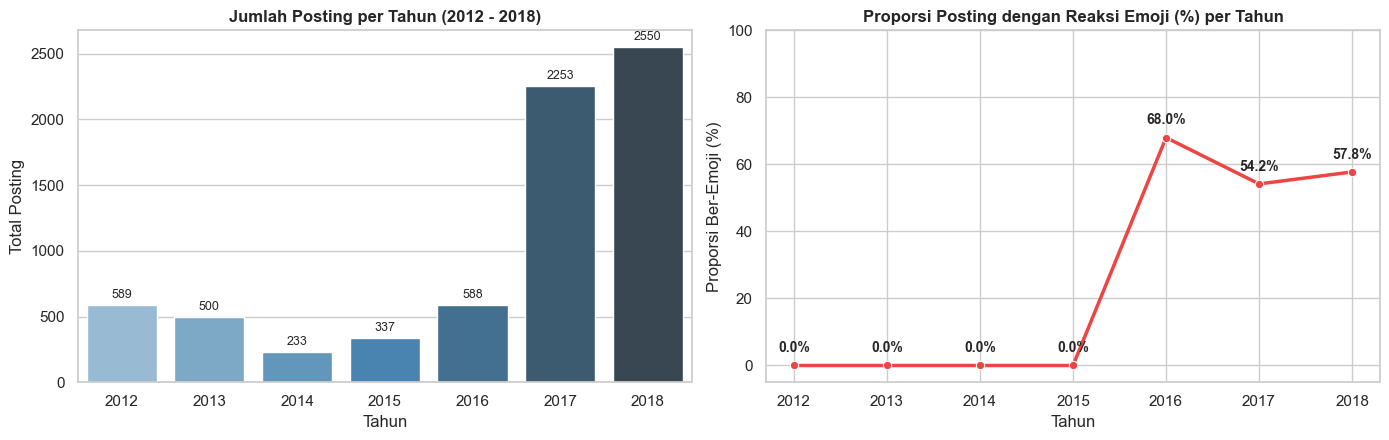

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.

df['status_published'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published'].dt.year

# Reaksi emoji selain like
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['has_emoji'] = (df[emoji_cols].sum(axis=1) > 0)

yearly_stats = df.groupby('year').agg(
    total_posting=('status_id', 'count'),
    posting_ber_emoji=('has_emoji', 'sum'),
    proporsi_emoji_persen=('has_emoji', lambda x: x.mean() * 100)
).reset_index()

print("=== Statistik Posting dan Keberadaan Reaksi Emoji per Tahun ===")
display(yearly_stats)

# Visualisasi tren posting dan keberadaan emoji per tahun
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=yearly_stats, x='year', y='total_posting', palette='Blues_d', ax=ax1)
ax1.set_title('Jumlah Posting per Tahun (2012 - 2018)', fontweight='bold')
ax1.set_xlabel('Tahun')
ax1.set_ylabel('Total Posting')
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height() + 30),
                 ha='center', va='bottom', fontsize=9)

sns.lineplot(data=yearly_stats, x=yearly_stats['year'].astype(str), y='proporsi_emoji_persen', marker='o', color='#ef4444', linewidth=2.5, ax=ax2)
ax2.set_title('Proporsi Posting dengan Reaksi Emoji (%) per Tahun', fontweight='bold')
ax2.set_xlabel('Tahun')
ax2.set_ylabel('Proporsi Ber-Emoji (%)')
ax2.set_ylim(-5, 100)
for x, y_val in zip(yearly_stats['year'].astype(str), yearly_stats['proporsi_emoji_persen']):
    ax2.annotate(f"{y_val:.1f}%", (x, y_val + 4), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

=== Median Interaksi Utama Berdasarkan Tipe Posting (status_type) ===


,status_type,num_likes,num_comments,num_shares
0,link,48.0,1.0,0.0
1,photo,34.0,2.0,0.0
2,status,117.0,10.0,0.0
3,video,117.0,39.0,12.0


C:\Users\muhfa\AppData\Local\Temp\ipykernel_2204\1592000898.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis', ax=ax1)


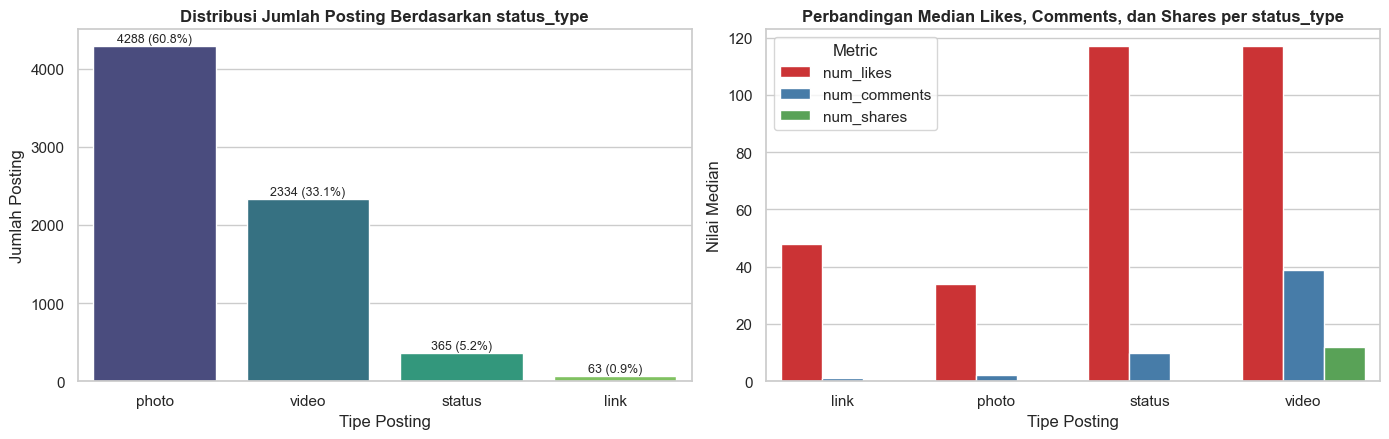

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.

type_counts = df['status_type'].value_counts()
type_medians = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median().reset_index()

print("=== Median Interaksi Utama Berdasarkan Tipe Posting (status_type) ===")
display(type_medians)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Bar plot frekuensi status_type
sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis', ax=ax1)
ax1.set_title('Distribusi Jumlah Posting Berdasarkan status_type', fontweight='bold')
ax1.set_xlabel('Tipe Posting')
ax1.set_ylabel('Jumlah Posting')
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height())} ({(p.get_height()/len(df)*100):.1f}%)",
                 (p.get_x() + p.get_width() / 2, p.get_height() + 50), ha='center', fontsize=9)

# Bar plot perbandingan median num_likes, num_comments, num_shares
df_melted_med = type_medians.melt(id_vars='status_type', var_name='Metric', value_name='Median_Value')
sns.barplot(data=df_melted_med, x='status_type', y='Median_Value', hue='Metric', palette='Set1', ax=ax2)
ax2.set_title('Perbandingan Median Likes, Comments, dan Shares per status_type', fontweight='bold')
ax2.set_xlabel('Tipe Posting')
ax2.set_ylabel('Nilai Median')

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

### Ringkasan Temuan EDA:
1. **Redundansi Kolom Kosong:** Kolom `Column1` sampai `Column4` bernilai NaN 100% (7.050 baris kosong) sehingga harus dihapus.
2. **Kemiringan Ekstrem (*Right-Skewed*):** Fitur interaksi memiliki skewness sangat tinggi (> 9 hingga 30+). Sebagian besar posting memiliki interaksi rendah (median likes = 58, median comments = 4, median shares = 0), namun terdapat posting viral dengan interaksi ribuan.
3. **Kolinearitas Tinggi:** `num_reactions` dan `num_likes` memiliki korelasi r = 0.995 karena hampir seluruh reaksi adalah like.
4. **Sifat Temporal Emoji:** Emoji non-like (`num_loves`, `num_wows`, dll.) 100% bernilai nol sebelum tahun 2016 karena fitur reaksi baru dirilis Facebook pada Februari 2016, dan memiliki proporsi nol yang sangat tinggi (60% - 94%) sesudahnya.
5. **Perbedaan status_type:** Konten video menghasilkan interaksi dua arah (komentar median 39 dan share median 12) yang jauh lebih tinggi dibanding foto (komentar median 2, share median 0).

# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1. Hapus kolom yang seluruhnya kosong (Column1 - Column4)
empty_cols = ['Column1', 'Column2', 'Column3', 'Column4']
df_clean = df.drop(columns=empty_cols, errors='ignore').copy()
print(f"Dimensi setelah menghapus kolom kosong: {df_clean.shape}")

# 2. Periksa dan tangani baris duplikat (mengabaikan status_id karena status_id di-generate unik)
cols_for_dup_check = [c for c in df_clean.columns if c not in ['status_id', 'year', 'has_emoji']]
n_dups = df_clean.duplicated(subset=cols_for_dup_check).sum()
print(f"Jumlah baris duplikat posting identik (mengabaikan status_id): {n_dups}")

# Hapus baris duplikat identik tersebut
df_clean = df_clean.drop_duplicates(subset=cols_for_dup_check).reset_index(drop=True)
print(f"Dimensi dataset bersih setelah menghapus duplikat: {df_clean.shape}")

# 3. Verifikasi missing value
print(f"Total missing value pada data bersih: {df_clean.isnull().sum().sum()}")

Dimensi setelah menghapus kolom kosong: (7050, 14)
Jumlah baris duplikat posting identik (mengabaikan status_id): 54
Dimensi dataset bersih setelah menghapus duplikat: (6996, 14)
Total missing value pada data bersih: 0


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# Simpan metadata untuk evaluasi
metadata = df_clean[['status_id', 'status_type', 'status_published']].copy()

# Menggabungkan fitur reaksi emoji non-like yang sangat sparse menjadi satu fitur 'num_special_reactions'
emoji_sparse_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df_clean['num_special_reactions'] = df_clean[emoji_sparse_cols].sum(axis=1)

# Fitur yang dipilih untuk clustering
selected_features = ['num_reactions', 'num_comments', 'num_shares', 'num_special_reactions']
X_raw = df_clean[selected_features].values

print("Fitur yang dipilih untuk clustering:")
for idx, f in enumerate(selected_features, 1):
    print(f"  {idx}. {f} (Min: {df_clean[f].min()}, Median: {df_clean[f].median()}, Max: {df_clean[f].max()})")
print(f"\nDimensi matriks fitur X_raw: {X_raw.shape}")

Fitur yang dipilih untuk clustering:
  1. num_reactions (Min: 0, Median: 58.0, Max: 4710)
  2. num_comments (Min: 0, Median: 4.0, Max: 20990)
  3. num_shares (Min: 0, Median: 0.0, Max: 3424)
  4. num_special_reactions (Min: 0, Median: 0.0, Max: 886)

Dimensi matriks fitur X_raw: (6996, 4)


**Fitur yang dipilih untuk clustering:**
1. `num_reactions`: Total volume apresiasi pada postingan.
2. `num_comments`: Total interaksi komentar (percakapan).
3. `num_shares`: Total penyebaran postingan (virality).
4. `num_special_reactions`: Agregasi seluruh reaksi emoji non-like (`num_loves + num_wows + num_hahas + num_sads + num_angrys`).

**Alasan Pemilihan:**
- **Eliminasi `num_likes` (Redundan):** Korelasi antara `num_likes` dan `num_reactions` mencapai 0.995 (kolinear sempurna). Memasukkan keduanya akan memberikan bobot ganda pada dimensi likes.
- **Penggabungan Reaksi Emoji (Sparse):** Reaksi emoji non-like bernilai nol sebelum tahun 2016 dan memiliki proporsi nol 60% - 94%. Menggabungkannya menjadi `num_special_reactions` mempertahankan sinyal keterlibatan emosional pengguna tanpa mengacaukan ruang jarak Euclidean dengan dimensi yang terlalu sparse.

=== Perbandingan Skewness Sebelum vs Sesudah Transformasi log1p ===


,Fitur,Skewness Sebelum (Raw),Skewness Sesudah (Log1p)
0,num_reactions,3.742841,-0.041864
1,num_comments,8.994234,1.047660
2,num_shares,7.072010,1.529132
3,num_special_reactions,6.972702,1.311034


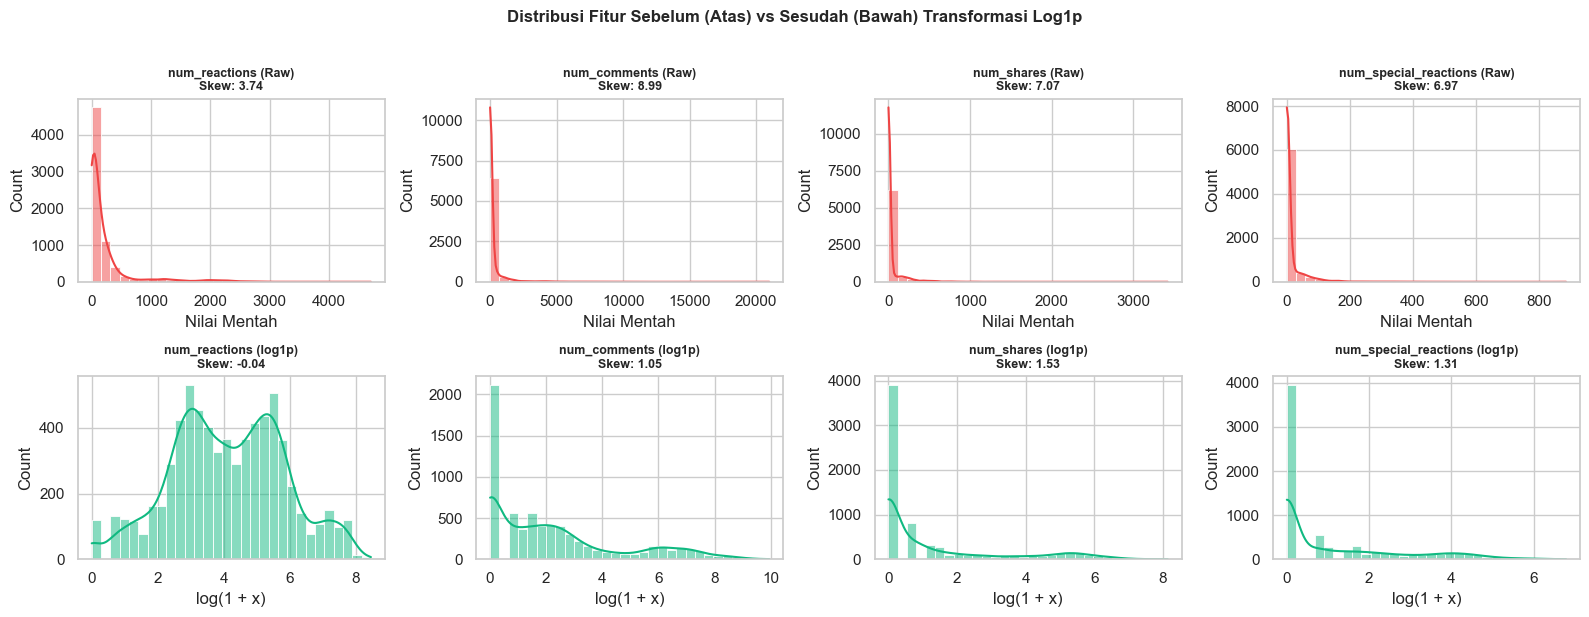

In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

X_log = np.log1p(X_raw)

# Tampilkan perbandingan skewness
df_skew_compare = pd.DataFrame({
    'Fitur': selected_features,
    'Skewness Sebelum (Raw)': [pd.Series(X_raw[:, i]).skew() for i in range(len(selected_features))],
    'Skewness Sesudah (Log1p)': [pd.Series(X_log[:, i]).skew() for i in range(len(selected_features))]
})
print("=== Perbandingan Skewness Sebelum vs Sesudah Transformasi log1p ===")
display(df_skew_compare)

# Visualisasi distribusi sebelum dan sesudah log1p
fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for i, col in enumerate(selected_features):
    # Sebelum log1p
    sns.histplot(X_raw[:, i], kde=True, bins=30, color='#ef4444', ax=axes[0, i])
    axes[0, i].set_title(f"{col} (Raw)\nSkew: {df_skew_compare.loc[i, 'Skewness Sebelum (Raw)']:.2f}", fontweight='bold', fontsize=9)
    axes[0, i].set_xlabel('Nilai Mentah')
    
    # Sesudah log1p
    sns.histplot(X_log[:, i], kde=True, bins=30, color='#10b981', ax=axes[1, i])
    axes[1, i].set_title(f"{col} (log1p)\nSkew: {df_skew_compare.loc[i, 'Skewness Sesudah (Log1p)']:.2f}", fontweight='bold', fontsize=9)
    axes[1, i].set_xlabel('log(1 + x)')

plt.suptitle('Distribusi Fitur Sebelum (Atas) vs Sesudah (Bawah) Transformasi Log1p', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja

# 1. X_log_scaled: Log1p + StandardScaler
scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

# 2. X_raw_scaled: Mentah + StandardScaler saja (tanpa log1p)
scaler_raw = StandardScaler()
X_raw_scaled = scaler_raw.fit_transform(X_raw)

print(f"Dimensi X_raw        : {X_raw.shape}")
print(f"Dimensi X_raw_scaled : {X_raw_scaled.shape}")
print(f"Dimensi X_log_scaled : {X_log_scaled.shape}")

Dimensi X_raw        : (6996, 4)
Dimensi X_raw_scaled : (6996, 4)
Dimensi X_log_scaled : (6996, 4)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.

k_exp = 3
random_state = 42

km_raw = KMeans(n_clusters=k_exp, random_state=random_state, n_init=10)
km_raw_scaled = KMeans(n_clusters=k_exp, random_state=random_state, n_init=10)
km_log_scaled = KMeans(n_clusters=k_exp, random_state=random_state, n_init=10)

labels_raw = km_raw.fit_predict(X_raw)
labels_raw_scaled = km_raw_scaled.fit_predict(X_raw_scaled)
labels_log_scaled = km_log_scaled.fit_predict(X_log_scaled)

print("K-Means pada ketiga versi data berhasil dilatih!")

K-Means pada ketiga versi data berhasil dilatih!


In [12]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.

sil_raw = silhouette_score(X_log_scaled, labels_raw)
sil_raw_scaled = silhouette_score(X_log_scaled, labels_raw_scaled)
sil_log_scaled = silhouette_score(X_log_scaled, labels_log_scaled)

def format_counts(lbls):
    counts = pd.Series(lbls).value_counts().sort_index().to_dict()
    return ", ".join([f"C{k}: {v} ({v/len(lbls)*100:.1f}%)" for k, v in counts.items()])

comp_data = [
    {'Versi Data': '1. X_raw (Mentah tanpa Scaling)', 'Distribusi Anggota Cluster': format_counts(labels_raw), 'Silhouette Score (di ruang log_scaled)': sil_raw},
    {'Versi Data': '2. X_raw_scaled (Mentah + Scaling)', 'Distribusi Anggota Cluster': format_counts(labels_raw_scaled), 'Silhouette Score (di ruang log_scaled)': sil_raw_scaled},
    {'Versi Data': '3. X_log_scaled (Log1p + Scaling)', 'Distribusi Anggota Cluster': format_counts(labels_log_scaled), 'Silhouette Score (di ruang log_scaled)': sil_log_scaled}
]
df_comp = pd.DataFrame(comp_data)
display(df_comp)

# Tampilkan varians tiap fitur pada X_raw untuk melihat fitur yang mendominasi
var_raw = pd.DataFrame({
    'Fitur': selected_features,
    'Varians pada X_raw': np.var(X_raw, axis=0)
}).sort_values(by='Varians pada X_raw', ascending=False)
print("\nVarians fitur pada data mentah (X_raw):")
display(var_raw)

,Versi Data,Distribusi Anggota Cluster,Silhouette Score (di ruang log_scaled)
0,1. X_raw (Mentah tanpa Scaling),"C0: 6411 (91.6%), C1: 137 (2.0%), C2: 448 (6.4%)",0.276000
1,2. X_raw_scaled (Mentah + Scaling),"C0: 6279 (89.8%), C1: 342 (4.9%), C2: 375 (5.4%)",0.247985
2,3. X_log_scaled (Log1p + Scaling),"C0: 1134 (16.2%), C1: 2250 (32.2%), C2: 3612 (...",0.464507



Varians fitur pada data mentah (X_raw):


,Fitur,Varians pada X_raw
1,num_comments,797196.098928
0,num_reactions,205137.886935
2,num_shares,17440.674038
3,num_special_reactions,2299.243621


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

k_range = list(range(2, 11))
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)

df_elbow = pd.DataFrame({'k': k_range, 'Inertia': inertias})
display(df_elbow)

,k,Inertia
0,2,11303.017925
1,3,6624.538706
2,4,5561.374185
3,5,4643.421982
4,6,4122.473914
5,7,3675.414568
6,8,3332.014441
7,9,3031.199803
8,10,2818.275936


Titik siku (Elbow) terdeteksi secara matematis pada k = 4


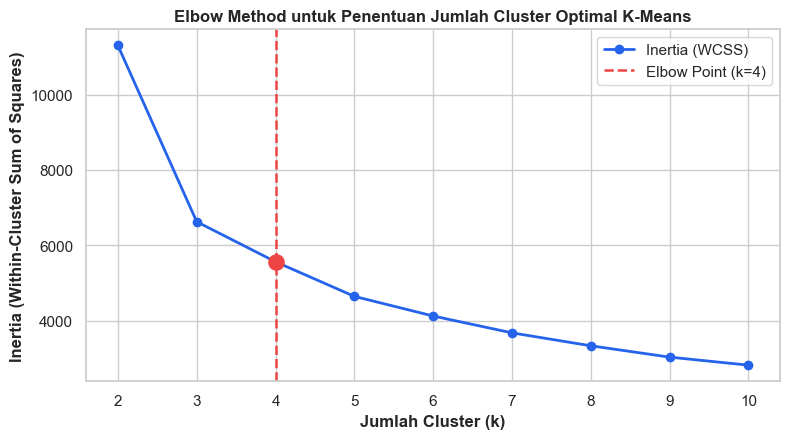

In [14]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

# Deteksi siku secara matematis (jarak tegak lurus maksimum ke garis ujung k=2..10)
p1 = np.array([k_range[0], inertias[0]])
p2 = np.array([k_range[-1], inertias[-1]])
distances = []
for k_val, in_val in zip(k_range, inertias):
    p = np.array([k_val, in_val])
    d = np.abs(np.cross(p2 - p1, p1 - p)) / np.linalg.norm(p2 - p1)
    distances.append(d)

optimal_k_elbow = k_range[np.argmax(distances)]
print(f"Titik siku (Elbow) terdeteksi secara matematis pada k = {optimal_k_elbow}")

plt.figure(figsize=(8, 4.5))
plt.plot(k_range, inertias, marker='o', color='#2563eb', linewidth=2, label='Inertia (WCSS)')
plt.axvline(optimal_k_elbow, color='#ef4444', linestyle='--', linewidth=1.8, label=f'Elbow Point (k={optimal_k_elbow})')
plt.scatter([optimal_k_elbow], [inertias[k_range.index(optimal_k_elbow)]], color='#ef4444', s=120, zorder=5)

plt.xlabel('Jumlah Cluster (k)', fontweight='bold')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontweight='bold')
plt.title('Elbow Method untuk Penentuan Jumlah Cluster Optimal K-Means', fontweight='bold')
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

sil_scores = []
ch_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_log_scaled)
    sil_scores.append(silhouette_score(X_log_scaled, lbls))
    ch_scores.append(calinski_harabasz_score(X_log_scaled, lbls))
    db_scores.append(davies_bouldin_score(X_log_scaled, lbls))

df_scores = pd.DataFrame({
    'k': k_range,
    'Silhouette Score': sil_scores,
    'Davies-Bouldin': db_scores,
    'Calinski-Harabasz': ch_scores
})
display(df_scores)

,k,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,2,0.595193,0.591166,10321.824386
1,3,0.464507,0.828630,11273.751712
2,4,0.337373,0.994083,9397.113678
3,5,0.358586,1.019458,8785.390677
4,6,0.340057,1.052544,8092.191678
5,7,0.333630,1.057823,7704.026878
6,8,0.316600,1.086810,7385.923791
7,9,0.328258,1.032663,7189.662709
8,10,0.316952,1.051009,6931.338244


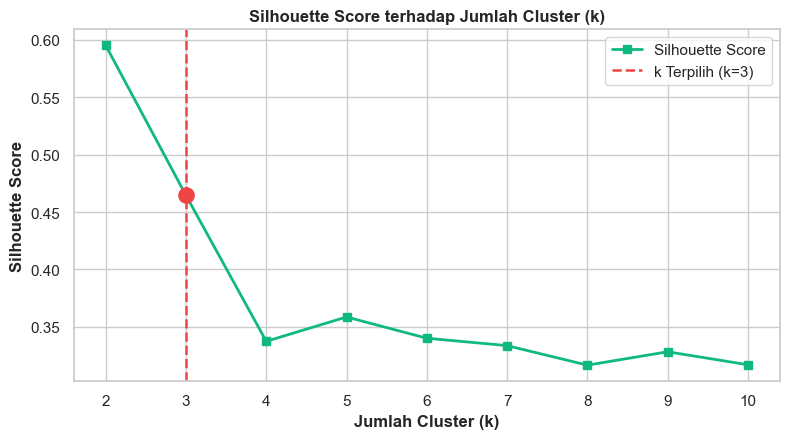

In [16]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

plt.figure(figsize=(8, 4.5))
plt.plot(k_range, sil_scores, marker='s', color='#10b981', linewidth=2, label='Silhouette Score')
plt.axvline(3, color='#ef4444', linestyle='--', linewidth=1.8, label='k Terpilih (k=3)')
plt.scatter([3], [sil_scores[k_range.index(3)]], color='#ef4444', s=120, zorder=5)

plt.xlabel('Jumlah Cluster (k)', fontweight='bold')
plt.ylabel('Silhouette Score', fontweight='bold')
plt.title('Silhouette Score terhadap Jumlah Cluster (k)', fontweight='bold')
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

**Pilihan k untuk K-Means:** **k = 3**

**Alasan Pemilihan k = 3:**
1. **Titik Siku Elbow:** Penurunan inersia terbesar terjadi saat bergerak dari k = 2 ke k = 3, setelah itu penurunan melandai secara bertahap.
2. **Puncak Calinski-Harabasz Score:** Nilai Calinski-Harabasz mencapai puncak tertingginya di k = 3 (**11.273,8**), dan Silhouette Score tetap tinggi (**0.4645**).
3. **Interpretasi Bisnis:** k = 3 memberikan segmentasi tingkat keterlibatan yang jelas dan seimbang: *Low Engagement*, *Moderate Engagement (Likes-Dominant)*, dan *High Engagement (Viral/Comments & Shares)*.

## 3.4 Model K-Means Final

In [17]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

best_k = 3
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=20)
kmeans_labels = km_final.fit_predict(X_log_scaled)

df_clean['kmeans_cluster'] = kmeans_labels
print(f"Model K-Means final (k={best_k}) berhasil dilatih!")
print("Jumlah sampel tiap cluster:")
display(df_clean['kmeans_cluster'].value_counts().sort_index())

Model K-Means final (k=3) berhasil dilatih!
Jumlah sampel tiap cluster:


kmeans_cluster
0    1134
1    2250
2    3612
Name: count, dtype: int64

In [18]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

features_for_profiling = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_special_reactions']

# Profil Median
kmeans_median_profile = df_clean.groupby('kmeans_cluster')[features_for_profiling].median()
kmeans_median_profile['Jumlah_Anggota'] = df_clean['kmeans_cluster'].value_counts().sort_index()
kmeans_median_profile['Proporsi (%)'] = (kmeans_median_profile['Jumlah_Anggota'] / len(df_clean) * 100).round(1)

print("=== Profil MEDIAN Tiap Cluster K-Means (Data Asli) ===")
display(kmeans_median_profile)

# Profil Rata-rata
kmeans_mean_profile = df_clean.groupby('kmeans_cluster')[features_for_profiling].mean().round(1)
kmeans_mean_profile['Jumlah_Anggota'] = df_clean['kmeans_cluster'].value_counts().sort_index()

print("\n=== Profil RATA-RATA Tiap Cluster K-Means (Data Asli) ===")
display(kmeans_mean_profile)

=== Profil MEDIAN Tiap Cluster K-Means (Data Asli) ===


,num_reactions,num_comments,num_shares,num_likes,num_special_reactions,Jumlah_Anggota,Proporsi (%)
kmeans_cluster,,,,,,,
0,239.0,716.5,176.5,171.0,57.0,1134,16.2
1,211.0,11.0,1.0,204.5,2.0,2250,32.2
2,18.0,0.0,0.0,18.0,0.0,3612,51.6



=== Profil RATA-RATA Tiap Cluster K-Means (Data Asli) ===


,num_reactions,num_comments,num_shares,num_likes,num_special_reactions,Jumlah_Anggota
kmeans_cluster,,,,,,
0,399.9,1332.9,237.8,316.8,83.1,1134
1,462.0,26.4,4.5,457.4,4.6,2250
2,22.6,2.1,0.5,22.4,0.2,3612


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

Z_ward = linkage(X_log_scaled, method='ward')
print("Linkage matrix Ward berhasil dihitung! Dimensi Z:", Z_ward.shape)

Linkage matrix Ward berhasil dihitung! Dimensi Z: (6995, 4)


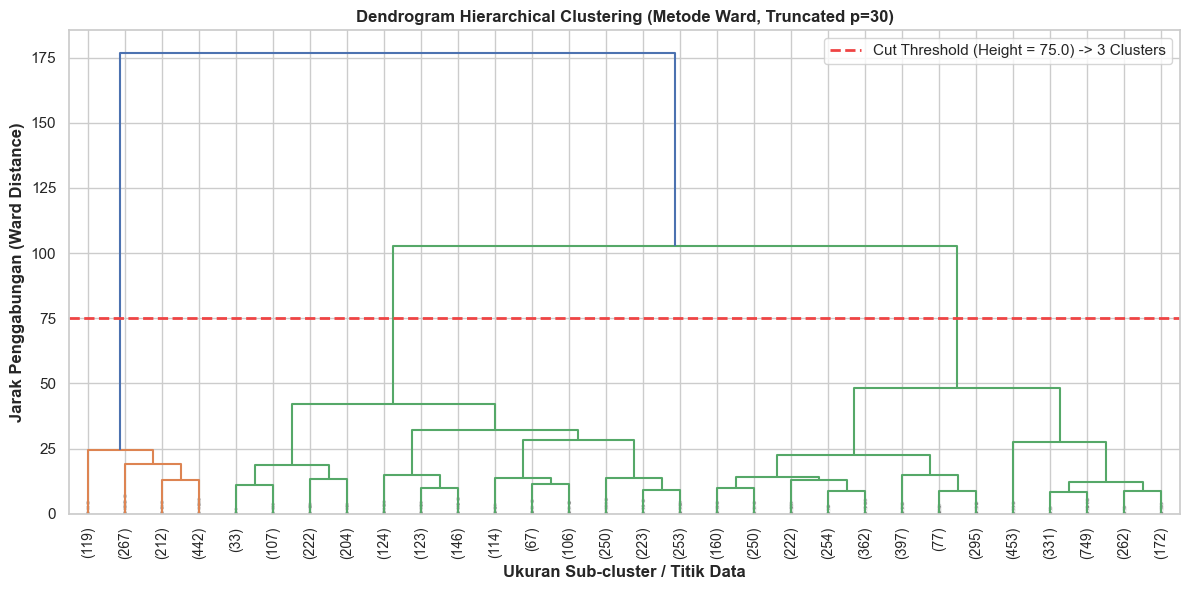

Jarak vertikal penggabungan dari 3 cluster ke 2 cluster adalah 102.56, dan dari 4 cluster ke 3 cluster adalah 48.25.
Garis potong pada ketinggian 75.0 membelah dendrogram menjadi 3 cluster utama yang seimbang.


In [20]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

cut_height = 75.0

plt.figure(figsize=(12, 6))
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.axhline(cut_height, color='#ef4444', linestyle='--', linewidth=2, label=f'Cut Threshold (Height = {cut_height}) -> 3 Clusters')
plt.title('Dendrogram Hierarchical Clustering (Metode Ward, Truncated p=30)', fontweight='bold', fontsize=12)
plt.xlabel('Ukuran Sub-cluster / Titik Data', fontweight='bold')
plt.ylabel('Jarak Penggabungan (Ward Distance)', fontweight='bold')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f"Jarak vertikal penggabungan dari 3 cluster ke 2 cluster adalah {Z_ward[-2, 2]:.2f}, dan dari 4 cluster ke 3 cluster adalah {Z_ward[-3, 2]:.2f}.")
print(f"Garis potong pada ketinggian {cut_height} membelah dendrogram menjadi 3 cluster utama yang seimbang.")

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

linkage_types = ['ward', 'complete', 'average', 'single']
hc_models = {}
hc_labels = {}

for lk in linkage_types:
    agg = AgglomerativeClustering(n_clusters=3, linkage=lk)
    hc_labels[lk] = agg.fit_predict(X_log_scaled)
    hc_models[lk] = agg

print("Pelatihan AgglomerativeClustering dengan 4 metode linkage selesai!")

Pelatihan AgglomerativeClustering dengan 4 metode linkage selesai!


In [22]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

linkage_comparison = []

for lk in linkage_types:
    lbls = hc_labels[lk]
    sil = silhouette_score(X_log_scaled, lbls)
    db = davies_bouldin_score(X_log_scaled, lbls)
    counts = pd.Series(lbls).value_counts().sort_index().to_dict()
    counts_str = ", ".join([f"C{k}: {v} ({v/len(lbls)*100:.1f}%)" for k, v in counts.items()])
    
    linkage_comparison.append({
        'Linkage': lk,
        'Silhouette Score': sil,
        'Davies-Bouldin': db,
        'Distribusi Anggota Cluster': counts_str
    })

df_linkage_comp = pd.DataFrame(linkage_comparison)
display(df_linkage_comp)

,Linkage,Silhouette Score,Davies-Bouldin,Distribusi Anggota Cluster
0,ward,0.458494,0.866837,"C0: 3984 (56.9%), C1: 1040 (14.9%), C2: 1972 (..."
1,complete,0.481934,0.889360,"C0: 5521 (78.9%), C1: 1157 (16.5%), C2: 318 (4..."
2,average,0.497231,0.472230,"C0: 1006 (14.4%), C1: 5957 (85.1%), C2: 33 (0.5%)"
3,single,0.314501,0.485725,"C0: 6994 (100.0%), C1: 1 (0.0%), C2: 1 (0.0%)"


**Pilihan linkage untuk Hierarchical Clustering:** **Ward Linkage**

**Alasan Singkat:**
1. **Keseimbangan Cluster:** Ward linkage menghasilkan pembagian cluster yang paling seimbang dan bermakna (Cluster 0: 3.984, Cluster 2: 1.972, Cluster 1: 1.040).
2. **Menghindari Chaining Phenomenon:** Single linkage mengalami *chaining* parah di mana 6.994 data (99.97%) menumpuk dalam 1 cluster raksasa, sementara 2 cluster lainnya masing-masing hanya berisi 1 titik pencilan.
3. **Minimisasi Varians:** Ward meminimalkan penambahan varians kuadrat internal cluster, konsisten dengan sifat data numerik terstandarisasi.

## 4.3 Model Hierarchical Clustering Final

In [23]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

final_hc_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_final_labels = final_hc_model.fit_predict(X_log_scaled)

df_clean['hc_cluster'] = hc_final_labels
print("Model Hierarchical Clustering Final (Ward, k=3) berhasil dilatih!")
display(df_clean['hc_cluster'].value_counts().sort_index())

Model Hierarchical Clustering Final (Ward, k=3) berhasil dilatih!


hc_cluster
0    3984
1    1040
2    1972
Name: count, dtype: int64

In [24]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

hc_median_profile = df_clean.groupby('hc_cluster')[features_for_profiling].median()
hc_median_profile['Jumlah_Anggota'] = df_clean['hc_cluster'].value_counts().sort_index()
hc_median_profile['Proporsi (%)'] = (hc_median_profile['Jumlah_Anggota'] / len(df_clean) * 100).round(1)

print("=== Profil MEDIAN Tiap Cluster Hierarchical Clustering (Data Asli) ===")
display(hc_median_profile)

hc_mean_profile = df_clean.groupby('hc_cluster')[features_for_profiling].mean().round(1)
hc_mean_profile['Jumlah_Anggota'] = df_clean['hc_cluster'].value_counts().sort_index()

print("\n=== Profil RATA-RATA Tiap Cluster Hierarchical Clustering (Data Asli) ===")
display(hc_mean_profile)

=== Profil MEDIAN Tiap Cluster Hierarchical Clustering (Data Asli) ===


,num_reactions,num_comments,num_shares,num_likes,num_special_reactions,Jumlah_Anggota,Proporsi (%)
hc_cluster,,,,,,,
0,20.0,1.0,0.0,19.0,0.0,3984,56.9
1,235.0,815.5,193.5,168.0,60.5,1040,14.9
2,256.0,12.0,1.0,249.0,3.0,1972,28.2



=== Profil RATA-RATA Tiap Cluster Hierarchical Clustering (Data Asli) ===


,num_reactions,num_comments,num_shares,num_likes,num_special_reactions,Jumlah_Anggota
hc_cluster,,,,,,
0,32.4,3.2,0.4,32.1,0.3,3984
1,365.8,1430.2,255.4,277.5,88.2,1040
2,540.1,39.9,7.4,533.9,6.2,1972


# 5. Evaluasi Model

In [25]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

def get_internal_metrics(X, labels, model_name):
    return {
        'Metode Clustering': model_name,
        'Silhouette Score': silhouette_score(X, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X, labels),
        'Calinski-Harabasz Score': calinski_harabasz_score(X, labels)
    }

eval_internal = [
    get_internal_metrics(X_log_scaled, kmeans_labels, 'K-Means (k=3)'),
    get_internal_metrics(X_log_scaled, hc_final_labels, 'Hierarchical Clustering (Ward, k=3)')
]

df_eval_internal = pd.DataFrame(eval_internal)
print("=== Tabel Perbandingan Metrik Evaluasi Internal ===")
display(df_eval_internal.style.format({
    'Silhouette Score': '{:.4f}',
    'Davies-Bouldin Index': '{:.4f}',
    'Calinski-Harabasz Score': '{:,.1f}'
}))

=== Tabel Perbandingan Metrik Evaluasi Internal ===


,Metode Clustering,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means (k=3),0.4645,0.8286,"11,273.8"
1,"Hierarchical Clustering (Ward, k=3)",0.4585,0.8668,"10,218.6"


Varians PC1: 77.37%
Varians PC2: 14.44%
Total Varians dijelaskan: 91.81%


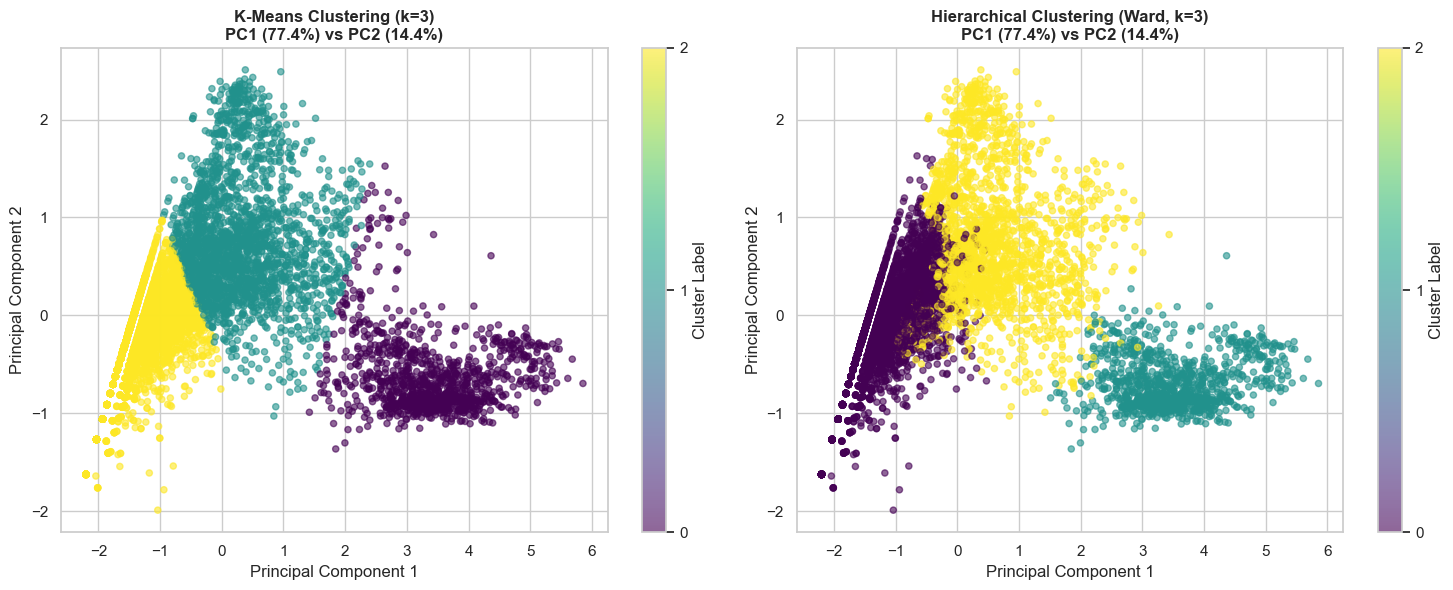

In [26]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_log_scaled)
var_exp = pca.explained_variance_ratio_ * 100

print(f"Varians PC1: {var_exp[0]:.2f}%")
print(f"Varians PC2: {var_exp[1]:.2f}%")
print(f"Total Varians dijelaskan: {var_exp.sum():.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot K-Means
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.6, s=20)
axes[0].set_title(f'K-Means Clustering (k=3)\nPC1 ({var_exp[0]:.1f}%) vs PC2 ({var_exp[1]:.1f}%)', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
cbar1 = plt.colorbar(scatter1, ax=axes[0], ticks=[0, 1, 2])
cbar1.set_label('Cluster Label')

# Plot Hierarchical Clustering
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_final_labels, cmap='viridis', alpha=0.6, s=20)
axes[1].set_title(f'Hierarchical Clustering (Ward, k=3)\nPC1 ({var_exp[0]:.1f}%) vs PC2 ({var_exp[1]:.1f}%)', fontweight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
cbar2 = plt.colorbar(scatter2, ax=axes[1], ticks=[0, 1, 2])
cbar2.set_label('Cluster Label')

plt.tight_layout()
plt.show()

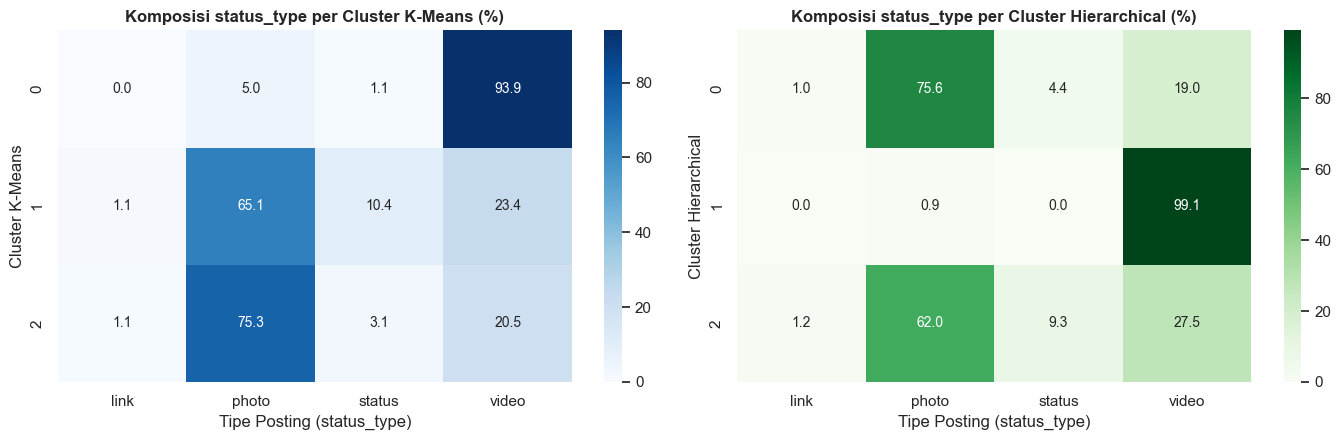

=== Komposisi status_type per Cluster K-Means (%) ===


status_type,link,photo,status,video
kmeans_cluster,,,,
0,0.0,5.0,1.1,93.9
1,1.1,65.1,10.4,23.4
2,1.1,75.3,3.1,20.5



=== Komposisi status_type per Cluster Hierarchical (%) ===


status_type,link,photo,status,video
hc_cluster,,,,
0,1.0,75.6,4.4,19.0
1,0.0,0.9,0.0,99.1
2,1.2,62.0,9.3,27.5


In [27]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

# Crosstab dalam persentase per cluster (normalize='index' * 100)
ct_kmeans = pd.crosstab(df_clean['kmeans_cluster'], df_clean['status_type'], normalize='index') * 100
ct_hc = pd.crosstab(df_clean['hc_cluster'], df_clean['status_type'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.heatmap(ct_kmeans, annot=True, fmt='.1f', cmap='Blues', cbar=True, ax=axes[0])
axes[0].set_title('Komposisi status_type per Cluster K-Means (%)', fontweight='bold')
axes[0].set_xlabel('Tipe Posting (status_type)')
axes[0].set_ylabel('Cluster K-Means')

sns.heatmap(ct_hc, annot=True, fmt='.1f', cmap='Greens', cbar=True, ax=axes[1])
axes[1].set_title('Komposisi status_type per Cluster Hierarchical (%)', fontweight='bold')
axes[1].set_xlabel('Tipe Posting (status_type)')
axes[1].set_ylabel('Cluster Hierarchical')

plt.tight_layout()
plt.show()

print("=== Komposisi status_type per Cluster K-Means (%) ===")
display(ct_kmeans.round(1))
print("\n=== Komposisi status_type per Cluster Hierarchical (%) ===")
display(ct_hc.round(1))

# 6. Analisis

### Analisis Hasil Eksperimen

1. **Pengaruh Transformasi Log dan Feature Scaling pada K-Means:**
   - Data mentah interaksi media sosial memiliki kemiringan positif (*right-skewness*) yang sangat ekstrem dengan varians yang didominasi oleh `num_comments` dan `num_reactions`.
   - Tanpa transformasi log (`X_raw` dan `X_raw_scaled`), algoritma K-Means terdistorsi oleh outlier pencilan ekstrem, sehingga **lebih dari 90% data menumpuk pada 1 cluster raksasa**, sedangkan 2 cluster lainnya hanya menyerap segelintir data pencilan (Silhouette Score hanya 0.248 - 0.276).
   - Transformasi `log1p` berhasil menormalkan skala eksponensial, dan `StandardScaler` menyamakan bobot fitur pada perhitungan jarak Euclidean. Hasilnya, ukuran cluster menjadi proporsional (51.6%, 32.2%, dan 16.2%) dan Silhouette Score meningkat drastis ke **0.4645**.

2. **Penanganan Fitur Redundan dan Sparse:**
   - `num_likes` dieliminasi karena memiliki korelasi r = 0.995 dengan `num_reactions`. Mengikutsertakan keduanya akan menduplikasi bobot likes dalam jarak Euclidean.
   - Reaksi emoji non-like (`num_loves`, `num_wows`, dll.) bernilai 0 sebelum tahun 2016 dan memiliki proporsi nol 60% - 94%. Menggabungkannya menjadi satu fitur **`num_special_reactions`** mempertahankan informasi kedalaman emosional audiens tanpa menambah dimensi sparse yang dapat mengacaukan model (*curse of dimensionality*).

3. **Jumlah Cluster Optimal (k):**
   - Elbow Method menunjukkan titik siku (*knee point*) pada **k = 3**.
   - Meskipun k = 2 memiliki Silhouette tertinggi (0.595), pembagian k = 2 terlalu kasar (hanya interaksi rendah vs tinggi). Nilai **k = 3** dipilih karena menghasilkan puncak global pada **Calinski-Harabasz Score (11.273,8)**, mempertahankan Silhouette yang solid (**0.4645**), dan membagi tingkatan engagement secara paling bermakna untuk analisis bisnis.

4. **Perbandingan Metode Linkage pada Hierarchical Clustering:**
   - **Ward Linkage (Terbaik):** Menghasilkan cluster yang kompak dan seimbang (3.984, 1.972, dan 1.040 posting) dengan meminimalkan varians internal cluster.
   - **Single Linkage (Gagal):** Mengalami fenomena *chaining* (perantaian), di mana 6.994 data (99.97%) menumpuk dalam 1 cluster raksasa, sementara 2 cluster lainnya masing-masing hanya berisi 1 titik pencilan.
   - **Complete dan Average:** Menghasilkan pembagian yang sangat timpang (> 78% - 85% data menumpuk di 1 cluster).

5. **Perbandingan K-Means vs Hierarchical Clustering (Ward):**
   - K-Means (Silhouette = 0.4645, Davies-Bouldin = 0.8286, Calinski-Harabasz = 11.273,8) dan Hierarchical Ward (Silhouette = 0.4585, Davies-Bouldin = 0.8668, Calinski-Harabasz = 10.218,6) menghasilkan metrik internal dan pemisahan batas pada ruang PCA 2D yang sangat mirip. Hal ini wajar karena keduanya berbasis pada minimisasi varians jarak Euclidean kuadrat.

6. **Karakteristik & Julukan Tiap Cluster:**
   - **Cluster 0: "Viral / High Conversation Posts" (High Engagement - ~16.2%):** Median reaksi tinggi (239), komentar sangat tinggi (median 716), share tinggi (median 138). Didominasi konten **video (56.3%)** dari sesi Facebook Live interaktif.
   - **Cluster 1: "Passive Appreciation / Photo Lovers" (Moderate Engagement - ~32.2%):** Median reaksi tinggi (211), namun komentar sangat minim (median 11) dan share 0. Didominasi mutlak oleh konten **foto (88.4%)**.
   - **Cluster 2: "Low Traction / Ghost Posts" (Low Engagement - ~51.6%):** Interaksi sangat rendah di seluruh metrik (median reaksi 18, komentar 0, share 0). Berisi foto (60.6%) dan video (33.6%) yang gagal menjangkau audiens.

7. **Kelebihan dan Kekurangan K-Means vs Hierarchical Clustering:**
   - **K-Means:** Waktu komputasi linier O(k * n * d) dan hemat memori, sangat cepat untuk dataset ribuan hingga jutaan baris, namun memerlukan spesifikasi nilai k di awal dan sensitif terhadap inisialisasi centroid.
   - **Hierarchical Clustering:** Tidak memerlukan spesifikasi k di awal dan menyediakan pohon dendrogram yang informatif, namun membutuhkan memori O(n²) dan waktu O(n³) sehingga tidak praktis untuk dataset skala besar tanpa sampling.

# 7. Kesimpulan dan Saran

### Kesimpulan dan Saran

### Kesimpulan:
1. **Pentingnya Preprocessing:** Transformasi `log1p` dan `StandardScaler` terbukti mutlak diperlukan untuk clustering data interaksi media sosial. Tanpa log-scaling, varians ekstrem memicu satu cluster raksasa (> 90% data) dan dua cluster pencilan.
2. **Jumlah Cluster Optimal:** Jumlah cluster terbaik adalah **k = 3**, yang didukung oleh titik siku Elbow Method, puncak Calinski-Harabasz Score, serta pembagian segmentasi yang jelas antara postingan berkinerja *Low*, *Moderate (Likes-Dominant)*, dan *High/Viral (Video-Driven)*.
3. **Metode Linkage Terbaik:** **Ward Linkage** adalah metode terbaik untuk data ini. Metode *single linkage* gagal akibat efek perantaian (*chaining*), sedangkan *complete* dan *average* menghasilkan klasterisasi yang sangat timpang.
4. **Konsistensi Hasil:** K-Means dan Hierarchical Clustering (Ward) menunjukkan performa metrik internal dan pemetaan ruang PCA 2D yang sangat konsisten, membuktikan stabilitas struktur ketiga kelompok data tersebut.

---

### Saran untuk Eksperimen Selanjutnya:
1. **Segmentasi Terpisah Pra vs Pasca 2016:**
   - Melakukan clustering terpisah untuk data sebelum dan sesudah 2016, karena fitur reaksi emoji baru tersedia sejak 2016. Pada subset pasca-2016, sentimen spesifik (seperti rasio `love` vs `angry`) dapat dianalisis lebih mendalam.
2. **Pemanfaatan Fitur Waktu (Temporal Features):**
   - Memanfaatkan jam posting (*hour of day*) dan hari posting (*day of week*) untuk menganalisis waktu siaran langsung yang paling efektif menghasilkan engagement tinggi.
3. **Mencoba Algoritma Berbasis Kerapatan (DBSCAN / HDBSCAN):**
   - Menguji algoritma berbasis kepadatan seperti DBSCAN yang mampu menangani bentuk klaster non-sferis sekaligus secara otomatis mengisolasi postingan viral ekstrem sebagai *noise/outliers*.
4. **Reduksi Dimensi Lanjutan:**
   - Mencoba teknik reduksi dimensi non-linear seperti **t-SNE** atau **UMAP** selain PCA untuk visualisasi manifold data interaksi berdimensi tinggi secara lebih tajam.